# PE vs Public Markets – Vintage Year Analysis

**Question:** *when* does private equity pay off? Do funds raised after a market crash outperform those raised at the peak of a cycle?

**Input:** Cambridge Associates, US PE (legacy definition) Benchmark Book, as of 30 Sep 2019 (`01_data_raw`)
**Outputs:** `02_data_clean/ca_uspe_legacy_vintage_2019q3.csv`, charts 03–04 in `05_outputs`


## 1. Setup

In [11]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pdfplumber

PROJECT = Path("..")
PDF = PROJECT / "01_data_raw" / "CA_USPE_Legacy_Benchmark_2019Q3.pdf"
CLEAN = PROJECT / "02_data_clean"
OUT = PROJECT / "05_outputs"
print("PDF found:", PDF.exists())

PDF found: True


## 2. Extract the tables from the PDF
Find each page by its title, then keep only the lines that start with a vintage year (1994–2017) and read the numbers on them.


In [12]:
def find_page(pdf, *keywords):
    """Return the text of the first page that contains all the keywords."""
    for page in pdf.pages:
        text = page.extract_text() or ""
        if all(k in text for k in keywords):
            return text
    raise ValueError(f"No page found with {keywords}")

def parse_rows(text, n_values):
    """Keep lines that start with a vintage year (1994-2017) and return their numbers."""
    rows = []
    for line in text.splitlines():
        line = line.strip()
        if re.match(r"^(199[4-9]|20[01]\d)\s", line):
            numbers = re.findall(r"-?[\d,]+\.?\d*", line)
            numbers = [float(n.replace(",", "")) for n in numbers]
            rows.append(numbers[: n_values + 1])
    return rows

with pdfplumber.open(PDF) as pdf:
    text_vintage = find_page(pdf, "BY FUND VINTAGE YEAR", "EQUAL-WEIGHTED")
    text_mpme = find_page(pdf, "MPME", "S&P 500 INDEX")

print(text_vintage[:600])

US PRIVATE EQUITY (LEGACY DEFINITION)
US PRIVATE EQUITY (LEGACY DEFINITION) AS OF SEPTEMBER 30, 2019
SINCE INCEPTION IRR& MULTIPLES BY FUND VINTAGE YEAR
Net to Limited Partners
POOLED ARITHMETIC EQUAL-WEIGHTED UPPER LOWER STANDARD
VINTAGE RETURN MEAN MEDIAN POOLED RETURN QUARTILE QUARTILE DEVIATION NUMBER
YEAR (%) (%) (%) (%) (%) (%) (%) DPI RVPI TVPI OF FUNDS
1994 23.97 13.56 9.68 14.18 23.40 1.02 15.17 2.41 0.00 2.41 21
1995 20.63 16.15 10.93 18.97 30.90 0.64 23.56 1.96 0.00 1.96 33
1996 10.63 9.69 8.27 8.75 12.30 1.77 18.45 1.60 0.00 1.60 36
1997 6.85 7.06 7.30 6.87 13.32 0.12 15.52 1.41 0.


## 3. Build the dataset

In [13]:
cols_vintage = ["vintage", "pooled_irr", "mean_irr", "median_irr", "eq_pooled_irr",
                "upper_quartile", "lower_quartile", "std_dev", "dpi", "rvpi", "tvpi", "n_funds"]
vintage = pd.DataFrame(parse_rows(text_vintage, 11), columns=cols_vintage)

cols_mpme = ["vintage", "n_funds", "pe_irr", "sp500_mpme_irr", "sp500_value_add_bps",
             "acwi_mpme_irr", "acwi_value_add_bps"]
mpme = pd.DataFrame(parse_rows(text_mpme, 6), columns=cols_mpme)

df = vintage.merge(mpme[["vintage", "sp500_mpme_irr", "sp500_value_add_bps",
                         "acwi_mpme_irr", "acwi_value_add_bps"]], on="vintage")
df[["vintage", "n_funds"]] = df[["vintage", "n_funds"]].astype(int)
df = df.set_index("vintage")
print(df.shape)
df[["pooled_irr", "median_irr", "upper_quartile", "lower_quartile", "tvpi", "n_funds",
    "sp500_mpme_irr", "sp500_value_add_bps"]]

(24, 15)


,pooled_irr,median_irr,upper_quartile,lower_quartile,tvpi,n_funds,sp500_mpme_irr,sp500_value_add_bps
vintage,,,,,,,,
1994,23.97,9.68,23.40,1.02,2.41,21,14.45,952.0
1995,20.63,10.93,30.90,0.64,1.96,33,12.95,768.0
1996,10.63,8.27,12.30,1.77,1.60,36,4.78,585.0
1997,6.85,7.30,13.32,0.12,1.41,49,1.55,531.0
1998,7.84,9.93,16.30,4.92,1.49,54,1.90,595.0
1999,15.20,12.13,18.06,5.12,1.91,51,2.92,1228.0
2000,15.04,12.39,21.14,7.48,1.83,75,5.73,931.0
2001,22.20,17.02,32.62,11.43,2.22,32,7.11,1510.0
2002,18.89,18.21,30.68,7.56,1.97,31,6.95,1194.0


## 4. Quality check
Compare a few extracted values with the PDF (pages 12 and 15).

In [14]:
checks = {
    (2006, "pooled_irr"): 8.44,
    (2009, "upper_quartile"): 24.65,
    (2001, "tvpi"): 2.22,
    (2008, "sp500_value_add_bps"): -300,
    (2017, "n_funds"): 58,
}
for (year, col), expected in checks.items():
    value = df.loc[year, col]
    status = "OK" if np.isclose(value, expected) else "CHECK"
    print(f"{year} {col:<22} expected {expected:>8}  got {value:>8}  {status}")

2006 pooled_irr             expected     8.44  got     8.44  OK
2009 upper_quartile         expected    24.65  got    24.65  OK
2001 tvpi                   expected     2.22  got     2.22  OK
2008 sp500_value_add_bps    expected     -300  got   -300.0  OK
2017 n_funds                expected       58  got       58  OK


## 5. Results by market cycle
Only mature vintages (≤ 2013) are used: CA notes that funds take about six years to settle into their final quartile.

In [15]:
df["iqr_spread_bps"] = (df["upper_quartile"] - df["lower_quartile"]) * 100
df["mature"] = df.index <= 2013   # funds need ~6 years to settle (as of Sep 2019)
df.to_csv(CLEAN / "ca_uspe_legacy_vintage_2019q3.csv")

periods = {
    "Post dot-com (2001-2003)": [2001, 2002, 2003],
    "Pre-GFC peak (2005-2008)": [2005, 2006, 2007, 2008],
    "Post-GFC (2009-2011)": [2009, 2010, 2011],
}
summary = pd.DataFrame({
    name: {
        "Avg pooled IRR (%)": df.loc[years, "pooled_irr"].mean(),
        "Avg S&P 500 mPME IRR (%)": df.loc[years, "sp500_mpme_irr"].mean(),
        "Avg value-add vs S&P 500 (bps)": df.loc[years, "sp500_value_add_bps"].mean(),
        "Avg top-bottom quartile spread (bps)": df.loc[years, "iqr_spread_bps"].mean(),
    } for name, years in periods.items()
}).T.round(1)
summary

,Avg pooled IRR (%),Avg S&P 500 mPME IRR (%),Avg value-add vs S&P 500 (bps),Avg top-bottom quartile spread (bps)
Post dot-com (2001-2003),19.0,6.5,1244.3,1939.0
Pre-GFC peak (2005-2008),9.9,10.3,-36.8,1111.5
Post-GFC (2009-2011),16.9,13.3,359.7,1220.3


## 6. Chart 3 – Value-add by vintage

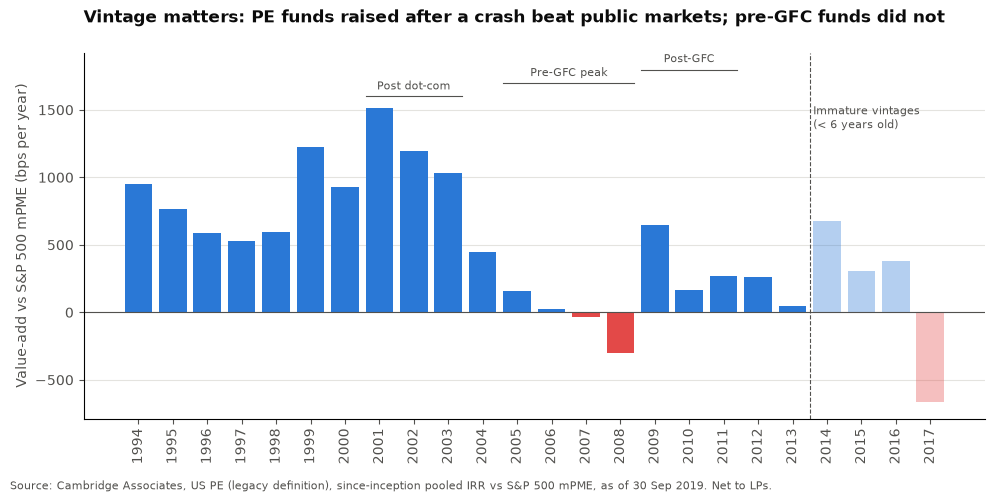

In [16]:
plt.rcParams.update({"font.family": "sans-serif", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, RED = "#2a78d6", "#e34948"

years = df.index.values
va = df["sp500_value_add_bps"].values
colors = [BLUE if v >= 0 else RED for v in va]
alphas = [1.0 if m else 0.35 for m in df["mature"]]

fig, ax = plt.subplots(figsize=(10, 5))
for yr, v, c, a in zip(years, va, colors, alphas):
    ax.bar(yr, v, color=c, alpha=a, width=0.8)
ax.axhline(0, color=MUTED, lw=0.8)
ax.axvline(2013.5, color=MUTED, lw=0.8, ls="--")
ax.text(2013.6, ax.get_ylim()[1] * 0.95, "Immature vintages\n(< 6 years old)", fontsize=8,
        color=MUTED, va="top")
for label, x0, x1 in [("Post dot-com", 2000.6, 2003.4), ("Pre-GFC peak", 2004.6, 2008.4),
                      ("Post-GFC", 2008.6, 2011.4)]:
    ax.annotate(label, ((x0 + x1) / 2, ax.get_ylim()[1] * 1.02), ha="center", fontsize=8,
                color=MUTED, annotation_clip=False)
    ax.plot([x0, x1], [ax.get_ylim()[1] * 0.99] * 2, color=MUTED, lw=0.8, clip_on=False)
ax.set_xticks(years, [str(y) for y in years], rotation=90)
ax.set_ylabel("Value-add vs S&P 500 mPME (bps per year)", color=MUTED)
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=MUTED)
ax.set_title("Vintage matters: PE funds raised after a crash beat public markets; pre-GFC funds did not",
             loc="left", fontsize=12, color=INK, fontweight="bold", pad=22)
fig.text(0.01, 0.01, "Source: Cambridge Associates, US PE (legacy definition), since-inception pooled IRR "
         "vs S&P 500 mPME, as of 30 Sep 2019. Net to LPs.", fontsize=8, color=MUTED)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(OUT / "03_value_add_by_vintage.png", dpi=200)
plt.show()

## 7. Chart 4 – Dispersion of fund returns by vintage

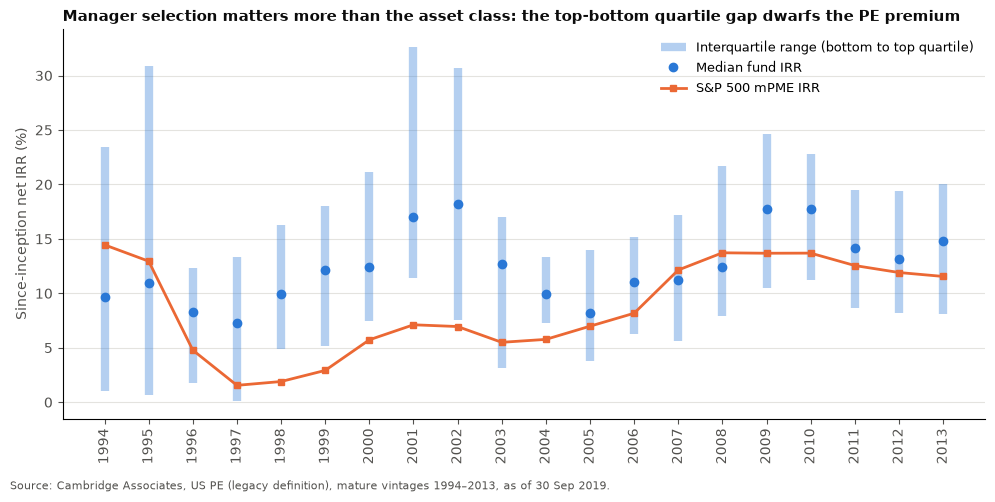

In [17]:
m = df[df["mature"]]
x = m.index.values
fig, ax = plt.subplots(figsize=(10, 5))
ax.vlines(x, m["lower_quartile"], m["upper_quartile"], color=BLUE, lw=6, alpha=0.35,
          label="Interquartile range (bottom to top quartile)")
ax.plot(x, m["median_irr"], "o", color=BLUE, ms=6, label="Median fund IRR")
ax.plot(x, m["sp500_mpme_irr"], color="#eb6834", lw=2, marker="s", ms=4,
        label="S&P 500 mPME IRR")
ax.set_xticks(x, [str(y) for y in x], rotation=90)
ax.set_ylabel("Since-inception net IRR (%)", color=MUTED)
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, loc="upper right", fontsize=9)
ax.set_title("Manager selection matters more than the asset class: the top-bottom quartile gap dwarfs the PE premium",
             loc="left", fontsize=11, color=INK, fontweight="bold")
fig.text(0.01, 0.01, "Source: Cambridge Associates, US PE (legacy definition), mature vintages 1994–2013, "
         "as of 30 Sep 2019.", fontsize=8, color=MUTED)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(OUT / "04_dispersion_by_vintage.png", dpi=200)
plt.show()

## 8. Quartile thresholds vs the market

In [18]:
m = df[df["mature"]].copy()
for col, name in [("upper_quartile", "top_q_vs_mpme"), ("median_irr", "median_vs_mpme"),
                  ("lower_quartile", "bottom_q_vs_mpme")]:
    m[name] = m[col] - m["sp500_mpme_irr"]
cols = ["top_q_vs_mpme", "median_vs_mpme", "bottom_q_vs_mpme"]
print("Average gap vs S&P 500 mPME (points a year):")
print(m[cols].mean().round(1))
print("\nVintages below the S&P 500 mPME:")
print((m[cols] < 0).sum())

Average gap vs S&P 500 mPME (points a year):
top_q_vs_mpme       11.5
median_vs_mpme       3.7
bottom_q_vs_mpme    -2.7
dtype: float64

Vintages below the S&P 500 mPME:
top_q_vs_mpme        0
median_vs_mpme       4
bottom_q_vs_mpme    14
dtype: int64


## 9. Can good vintages be timed?
Does a vintage's value-add depend on how the S&P 500 did before launch (3 prior years), or during the fund's life?

Correlation with S&P 500 return before launch: +0.12
Correlation with S&P 500 return during fund life: -0.38


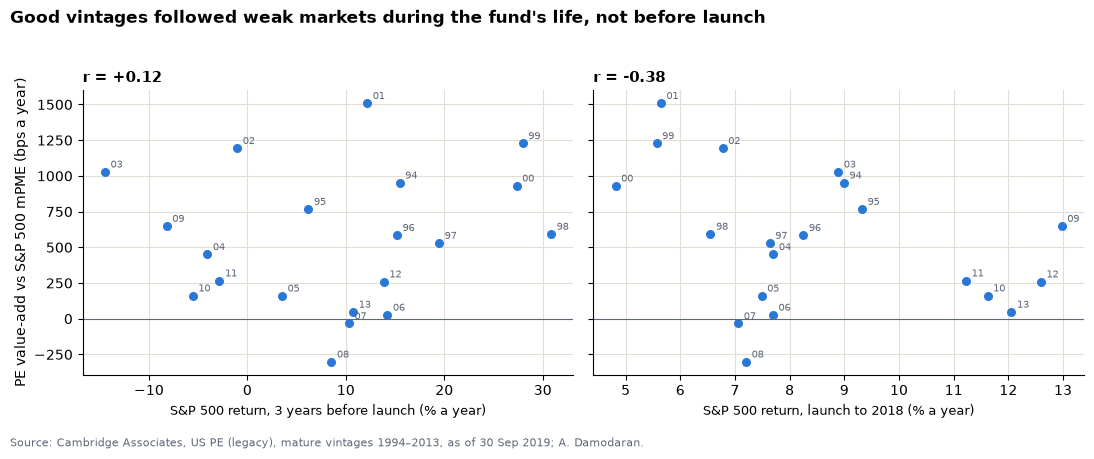

In [19]:
pub = pd.read_csv("../02_data_clean/public_annual_returns_1928_2025.csv")
year_col = pub.columns[0]
sp_col = [c for c in pub.columns if "S&P" in c or "sp500" in c.lower()][0]
sp = pub.set_index(year_col)[sp_col]
if sp.abs().max() > 1:          # stored in % -> convert to decimal
    sp = sp / 100

def cagr(start, end):
    r = sp.loc[start:end]
    return ((1 + r).prod() ** (1 / len(r)) - 1) * 100

pooled_col = [c for c in df.columns if "pooled" in c.lower()][0]
t = df[df["mature"]].copy()
t["value_add_bps"] = (t[pooled_col] - t["sp500_mpme_irr"]) * 100
t["prior_cagr"] = [cagr(v - 3, v - 1) for v in t.index]   # 3 years before launch
t["life_cagr"]  = [cagr(v, 2018) for v in t.index]        # launch to end-2018

r_before = t["value_add_bps"].corr(t["prior_cagr"])
r_during = t["value_add_bps"].corr(t["life_cagr"])
print(f"Correlation with S&P 500 return before launch: {r_before:+.2f}")
print(f"Correlation with S&P 500 return during fund life: {r_during:+.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, col, r, xlabel in [
    (axes[0], "prior_cagr", r_before, "S&P 500 return, 3 years before launch (% a year)"),
    (axes[1], "life_cagr",  r_during, "S&P 500 return, launch to 2018 (% a year)")]:
    ax.scatter(t[col], t["value_add_bps"], color="#2a78d6", s=30)
    for v, row in t.iterrows():
        ax.annotate(str(v)[-2:], (row[col], row["value_add_bps"]),
                    xytext=(4, 3), textcoords="offset points", fontsize=7, color="#5F6878")
    ax.axhline(0, color="#5F6878", lw=0.8)
    ax.set_xlabel(xlabel, fontsize=9)
    ax.set_title(f"r = {r:+.2f}", loc="left", fontsize=11, fontweight="bold")
    ax.grid(color="#E2DED5", lw=0.8); ax.set_axisbelow(True)
axes[0].set_ylabel("PE value-add vs S&P 500 mPME (bps a year)")
fig.suptitle("Good vintages followed weak markets during the fund's life, not before launch",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.text(0.01, 0.01, "Source: Cambridge Associates, US PE (legacy), mature vintages 1994–2013, as of 30 Sep 2019; A. Damodaran.",
         fontsize=8, color="#5F6878")
fig.tight_layout(rect=(0, 0.04, 1, 0.95))
fig.savefig(OUT / "06_vintage_timing_test.png", dpi=200)
plt.show()

## Key takeaways
**PE’s edge sits with the managers, not with the asset class.**

1. **Vintage matters, but could not be timed.** Value-add ranged from −300 to +1,510 bps a year. It tracks public markets during a fund's life (r = −0.41), not the S&P 500's return before launch (r = +0.12): the 1999–2000 vintages, raised at the dot-com peak, were among the best.
2. **Dispersion is a risk, not an edge.** On average, the top-quartile threshold beat the S&P 500 mPME by 11.5 points a year; the bottom-quartile threshold trailed it by 2.7 points (below the market in 14 of 20 vintages).
3. **Limitations:** quartile thresholds are fund-level IRRs while the mPME uses pooled cash flows; data as of Sep 2019; small samples for some vintages.